# 06 — Reality vs model: dynamic visualisation

Notebook 05 produced, for every 25 km cell and every year, the probability of having toad records. This notebook turns it into:

1. **An interactive page** (`docs/index.html`, published with GitHub Pages) with a year slider from 1935 to 2035:
   - **1935–2015, history:** what happened. These years are the model's training data.
   - **2016–2025, backtest:** the model trained with data up to 2015, next to what actually happened. This is the honest test of the model.
   - **2026–2035, forecast:** the model retrained with data up to 2025.
2. **An animated GIF** of the same comparison for the README.

The model's output is shown as a **probability gradient**, not as occupied / not occupied. A threshold would read more easily but would hide the uncertainty, which is part of the result.

In [1]:
import base64
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.animation import FuncAnimation, PillowWriter
from matplotlib.colors import LinearSegmentedColormap

PROJECT_ROOT = Path.cwd().parent
sys.path.append(str(PROJECT_ROOT / "src"))
from environment import environmental_grid, major_rivers

PROCESSED = PROJECT_ROOT / "data" / "processed"
FIGURES = PROJECT_ROOT / "figures"
SITE = PROJECT_ROOT / "docs"
CELL_SIZE_M = 25_000
CELL_KM2 = (CELL_SIZE_M / 1000) ** 2
SCENARIOS = ["observed niche", "expanded niche"]
BACKTEST_YEARS = range(2016, 2026)
FORECAST_YEARS = range(2026, 2036)
MAP_RIVER_DISCHARGE_M3S = 20

backtest = {s: pd.read_csv(PROCESSED / f"backtest_{s.replace(' ', '_')}.csv") for s in SCENARIOS}
forecast = {s: pd.read_csv(PROCESSED / f"forecast_{s.replace(' ', '_')}.csv") for s in SCENARIOS}
summary = pd.read_csv(PROCESSED / "simulation_summary_by_year.csv")

cells = forecast["observed niche"][["cx", "cy", "lon", "lat", "first_year"]]
for table in [*backtest.values(), *forecast.values()]:
    assert table[["cx", "cy"]].equals(cells[["cx", "cy"]]), "All tables must share the same cell order"
print(f"{len(cells):,} cells; {np.isfinite(cells['first_year']).sum():,} with records by 2025")

12,312 cells; 1,310 with records by 2025


## 1. Observed history, measured the same way as the simulations

Same definitions as notebook 05: occupied area = cells with records × 625 km²; western front = third westernmost occupied cell west of 141°E; Pilbara = 116–121°E, 19–23°S.

In [2]:
first_year = cells["first_year"].to_numpy()
x_km = (cells["cx"].to_numpy() + 0.5) * CELL_SIZE_M / 1000
west = (cells["lon"] < 141).to_numpy()
pilbara = (cells["lon"].between(116, 121) & cells["lat"].between(-23, -19)).to_numpy()


def western_front(occupied: np.ndarray) -> float | None:
    xs = np.sort(x_km[occupied & west])
    return float(xs[2]) if len(xs) >= 3 else None


first_record = int(first_year[np.isfinite(first_year)].min())
observed = pd.DataFrame([
    {
        "year": year,
        "area": (first_year <= year).sum() * CELL_KM2,
        "front_x": western_front(first_year <= year),
        "pilbara": bool((first_year[pilbara] <= year).any()),
    }
    for year in range(first_record, 2026)
])
front_start = observed.dropna(subset=["front_x"]).iloc[0]
print(f"Western front defined from {int(front_start['year'])}; it has advanced "
      f"{front_start['front_x'] - western_front(first_year <= 2025):.0f} km west since then")
observed.tail()

Western front defined from 1969; it has advanced 1800 km west since then


,year,area,front_x,pilbara
86,2021,713125.0,-737.5,False
87,2022,750625.0,-762.5,False
88,2023,765625.0,-837.5,False
89,2024,785625.0,-862.5,False
90,2025,805625.0,-862.5,False


## 2. The interactive page

The probabilities are stored as one byte per cell and year (0–255) and embedded in the HTML, so the page is a single self-contained file with no server and no external libraries. A button overlays the climate zones and major rivers from notebook 03, to see where the front meets the desert.

In [3]:
def probability_bytes(table: pd.DataFrame, years) -> str:
    values = np.concatenate([table[f"p_{year}"].to_numpy() for year in years])
    return base64.b64encode(np.round(values * 255).astype(np.uint8).tobytes()).decode()


ZONES = ["Desert (BW)", "Semi-arid (BS)", "Humid, summer rain", "Humid, winter rain", "Humid, year-round rain"]
zones = cells[["cx", "cy"]].merge(environmental_grid(CELL_SIZE_M)[["cx", "cy", "climate_zone"]], how="left", on=["cx", "cy"])
assert zones["climate_zone"].isin(ZONES).all() and len(zones) == len(cells)

rivers = major_rivers(MAP_RIVER_DISCHARGE_M3S).geometry.simplify(5_000)
river_lines = [
    [round(value / CELL_SIZE_M, 2) for xy in line.coords for value in xy[:2]]
    for geometry in rivers for line in getattr(geometry, "geoms", [geometry])
]

pilbara_cells = cells.loc[pilbara]
payload = {
    "zone": zones["climate_zone"].map(ZONES.index).tolist(),
    "rivers": river_lines,
    "cx": cells["cx"].tolist(),
    "cy": cells["cy"].tolist(),
    "first_year": [int(y) if np.isfinite(y) else 0 for y in first_year],
    "first_year_min": first_record,
    "prob": {s: {"backtest": probability_bytes(backtest[s], BACKTEST_YEARS),
                 "forecast": probability_bytes(forecast[s], FORECAST_YEARS)} for s in SCENARIOS},
    "summary": summary.round(4).to_dict(orient="records"),
    "observed": observed.round(4).astype(object).where(observed.notna(), None).to_dict(orient="records"),
    "front_start_x": front_start["front_x"],
    "front_start_year": int(front_start["year"]),
    "pilbara_box": [int(pilbara_cells["cx"].min()), int(pilbara_cells["cy"].min()),
                    int(pilbara_cells["cx"].max()), int(pilbara_cells["cy"].max())],
}

template = (PROJECT_ROOT / "src" / "dashboard_template.html").read_text(encoding="utf-8")
assert template.count("/*__DATA__*/null") == 1
SITE.mkdir(exist_ok=True)
page = SITE / "index.html"
page.write_text(template.replace("/*__DATA__*/null", json.dumps(payload, separators=(",", ":"))), encoding="utf-8")
print(f"Wrote {page.name}: {page.stat().st_size / 1e6:.2f} MB")

Wrote index.html: 1.07 MB


## 3. GIF for the README

Observed niche scenario (the conservative one), 1990–2035. Left: reality. Right: the model, trained up to 2015 for the backtest years and up to 2025 for the forecast years. Grey cells were already occupied when the model started; dark cells on the left were recorded afterwards.

In [4]:
RAMP = LinearSegmentedColormap.from_list("ramp", ["#fcfdbf", "#feb078", "#f1605d", "#b5367a", "#721f81", "#2c115f"])
LAND = np.array([0.93, 0.91, 0.87, 1])
BASELINE = np.array([0.65, 0.64, 0.6, 1])
INK = np.array([0.23, 0.06, 0.44, 1])

cx, cy = cells["cx"].to_numpy(), cells["cy"].to_numpy()
cols, rows = cx - cx.min(), cy.max() - cy
shape = (rows.max() + 1, cols.max() + 1)


def raster(colours: np.ndarray) -> np.ndarray:
    image = np.ones((*shape, 4))
    image[rows, cols] = colours
    return image


def frame_colours(year: int, scenario: str = "observed niche"):
    baseline = year if year < 2016 else 2015 if year < 2026 else 2025
    known = first_year <= baseline
    reality = np.tile(LAND, (len(cells), 1))
    reality[known] = INK if year < 2016 else BASELINE
    reality[(first_year > baseline) & (first_year <= min(year, 2025))] = INK
    model = np.tile(LAND, (len(cells), 1))
    model[known] = INK if year < 2016 else BASELINE
    if year >= 2016:
        source = backtest[scenario] if year < 2026 else forecast[scenario]
        p = source[f"p_{year}"].to_numpy()
        shown = ~known & (p >= 0.01)
        model[shown] = RAMP(p[shown])
    return raster(reality), raster(model), baseline


fig, axes = plt.subplots(1, 2, figsize=(9, 4.6))
images = []
for ax in axes:
    images.append(ax.imshow(raster(np.tile(LAND, (len(cells), 1))), interpolation="nearest"))
    ax.set_axis_off()
title = fig.suptitle("", fontsize=13)
fig.colorbar(plt.cm.ScalarMappable(cmap=RAMP), ax=axes, shrink=0.6, label="Model: P(cell has toad records)")


def update(year):
    reality, model, baseline = frame_colours(year)
    images[0].set_data(reality)
    images[1].set_data(model)
    axes[0].set_title("Reality" + (" (not observed yet, showing 2025)" if year > 2025 else ""), fontsize=10)
    axes[1].set_title("Model: training period" if year < 2016 else f"Model trained with data up to {baseline}", fontsize=10)
    phase = "history" if year < 2016 else "backtest" if year < 2026 else "forecast"
    title.set_text(f"Cane toad invasion, {year} ({phase})")
    return images


years = list(range(1990, 2036)) + [2035] * 6
gif_path = FIGURES / "06_reality_vs_model.gif"
FuncAnimation(fig, update, frames=years).save(gif_path, writer=PillowWriter(fps=3), dpi=80)
plt.close(fig)
print(f"Saved {gif_path.name}: {gif_path.stat().st_size / 1e6:.1f} MB")

Saved 06_reality_vs_model.gif: 0.2 MB


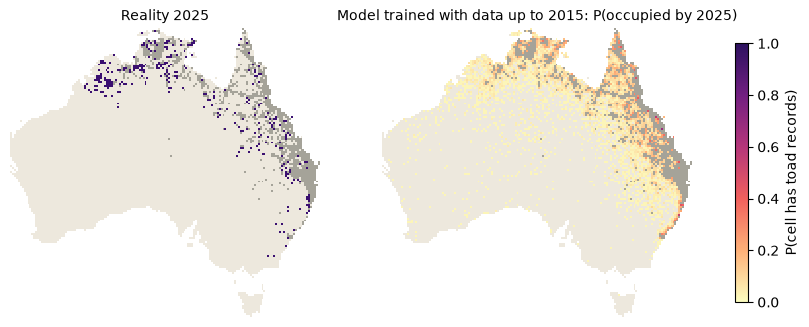

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5.6))
reality, model, _ = frame_colours(2025)
for ax, image, label in zip(axes, [reality, model], ["Reality 2025", "Model trained with data up to 2015: P(occupied by 2025)"]):
    ax.imshow(image, interpolation="nearest")
    ax.set_axis_off()
    ax.set_title(label, fontsize=10)
fig.colorbar(plt.cm.ScalarMappable(cmap=RAMP), ax=axes, shrink=0.6, label="P(cell has toad records)")
plt.savefig(FIGURES / "06_reality_vs_model_2025.png", dpi=150, bbox_inches="tight")

## Takeaways

- The backtest years are the core of the page: they show the forecast the model would have made in 2015 next to what happened, without the model having seen any of it.
- The page also shows **where the model fails**: new records behind the front (the survey-effort effect from notebook 05) appear on the reality map where the model gave low probability.
- The forecast years have nothing to compare with yet. As new records are uploaded, the page can be rebuilt and the 2026+ forecast checked the same way.